# 2D RF: error convergence, PCA and CPU allocation

The reference results contain 50 paired field realizations. The block-matrix illustration uses a separate seed 2026.

In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import FuncNorm
from matplotlib.ticker import FuncFormatter, FormatStrFormatter
from IPython.display import display
HERE=Path.cwd()
DATA=HERE/'Data'
FIG=HERE/'Figures'
FIG.mkdir(exist_ok=True)
from PCA_Theta import load_result
METHODS=['random_ols','lhs_ols','theta_ols','pca_theta_ols','qv_theta_ols','qv_pca_theta_ols']
LABELS=['Random-OLS','LHS-OLS',r'$\Theta$-OLS',r'PCA-$\Theta$-OLS',r'$\eta$-$\Theta$-OLS',r'$\eta$-PCA-$\Theta$-OLS']
COLORS=['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#17becf']
CONTRAST_POWER=2.0

In [2]:
TABLE=DATA/'timing.csv'
PHASES = [
    ("Degree selection and OLS", "#79A7CF", ["degree_selection_and_ols"]),
    ("PCA", "#9977B6", ["pca_and_common_basis"]),
    (r"$\Theta$ sampling", "#E99750", ["criterion_response_evaluation", "distance_search", "criterion_aggregation_and_batch"]),
    ("Model evaluation and other", "#ABACB3", ["model_evaluation", "other"]),
]


def draw_breakdown(ax, compact=False):
    with TABLE.open(encoding="utf-8-sig", newline="") as stream:
        rows = [r for r in csv.DictReader(stream) if (r["example"], r["mode"], r["clock"]) == ("rf2d", "common", "cpu_seconds")]
    means, deviations = [], []
    for method in METHODS[2:]:
        runs = [r for r in rows if r["method"] == method]
        assert sorted(int(r["repeat"]) for r in runs) == list(range(50))
        times = np.array([[sum(float(r[k]) for k in keys) for _, _, keys in PHASES] for r in runs])
        total = np.array([float(r["construction_total"]) for r in runs])
        np.testing.assert_allclose(times.sum(axis=1), total, atol=1e-9)
        means.append(times.mean(axis=0))
        deviations.append(total.std(ddof=1))
    y = np.arange(len(METHODS[2:]))
    left = np.zeros(len(y))
    for (label, color, _), values in zip(PHASES, np.array(means).T):
        ax.barh(y, values, left=left, color=color, label=label, height=.62)
        for yi, start, value in zip(y, left, values):
            if value >= 9:
                ax.text(start + value/2, yi, f"{value:.1f} s", ha="center", va="center", fontsize=12)
        left += values
    ax.errorbar(left, y, xerr=deviations, fmt="none", ecolor="#222222", lw=1, capsize=2.5)
    for yi, total, sd in zip(y, left, deviations):
        ax.text(total+sd+1.2, yi, f"{total:.1f} s", va="center", fontsize=12)
    ax.set(yticks=y, yticklabels=LABELS[2:], ylim=(y[-1]+.5,-.5), xlim=(0,124 if compact else 118),
           xticks=(0,30,60,90,120) if compact else range(0,101,20), xlabel="Mean construction CPU time (s)")
    ax.tick_params(axis="y", length=0, pad=7)
    return left
METRICS = ("nrmse", "nmae", "nmaxae")
N = np.arange(30, 1001, 10)
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 14, "legend.fontsize": 14,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.linewidth": .8,
    "axes.spines.right": False, "axes.spines.top": False, "axes.grid": False,
})


def load_2d():
    with np.load(DATA/'results.npz',allow_pickle=False) as z:
        np.testing.assert_array_equal(z['n'],N)
        return {m:tuple(z[m+'_'+k] for k in ('logs','times','pcs')) for m in METHODS}



def export(fig, name, folder=FIG):
    fig.savefig(folder / (name + ".pdf"), dpi=260, facecolor="white")
    display(fig); plt.close(fig)


def convergence(data, *, name="rf_normalized_log_convergence", folder=FIG, fixed_from=None):
    fig, axes = plt.subplots(1, 3, figsize=(9, 3.38))
    for idx, (ax, title) in enumerate(zip(axes, ("NRMSE", "NMAE", "NMaxAE"))):
        extrema = []
        for method, color in zip(METHODS, COLORS):
            a = data[method][0][:, idx]
            mean, sd = a.mean(0), a.std(0, ddof=1)
            extrema.extend([mean.min(), mean.max(), np.quantile(mean - sd, .01), np.quantile(mean + sd, .99)])
            ax.fill_between(N, mean-sd, mean+sd, color=color, alpha=.065, linewidth=0)
            for bound in (mean-sd, mean+sd):
                ax.plot(N, bound, ls="--", color=color, lw=.44, alpha=.48)
            ax.plot(N, mean, color=color, lw=1.5)
        lo, hi = int(np.floor(min(extrema))), int(np.ceil(max(extrema)))
        step = 2
        lo = step*(lo//step)
        hi = max(lo+3*step, step*int(np.ceil(hi/step)))
        ax.set(xlim=(0,1020), xticks=(0,500,1000), ylim=(lo,hi), yticks=np.arange(lo,hi+1,step), title=title)
        if fixed_from is not None:
            ax.axvline(fixed_from, color=".3", lw=.9, ls=":", zorder=0)
    fig.text(.032,.62,r"$\log_{10}(\varepsilon^{\mathrm{norm}})$",rotation=90,ha="center",va="center")
    fig.text(.52,.275,"Number of training samples",ha="center")
    fig.subplots_adjust(left=.093,right=.981,bottom=.42,top=.885,wspace=.30)
    handles = [Line2D([], [], color=c, lw=2, label=l) for c,l in zip(COLORS,LABELS)]
    fig.legend(handles=handles,loc="lower center",ncol=3,bbox_to_anchor=(.5,.008),handlelength=1.6,columnspacing=1.25,handletextpad=.4,borderaxespad=0)
    export(fig,name,folder)


def pca_axes(breakdown=False):
    fig = plt.figure(figsize=(9.7,3.98) if breakdown else (9,3.22))
    left = fig.add_axes([.078,.37,.33,.56] if breakdown else [.083,.31,.355,.65])
    right = fig.add_axes([.605,.37,.37,.56] if breakdown else [.662,.31,.312,.65])
    left.set(xlabel="Principal component", ylabel="Contribution ratio", xticks=[1,5,10,15,20], xlim=(.35,20.65))
    left.axhline(.01,ls="--",lw=.9,color="black",zorder=1)
    for ax, panel in ((left,"(a)"),(right,"(b)")):
        box = ax.get_position()
        fig.text((box.x0+box.x1)/2,.17 if breakdown else .079,panel,ha="center",va="center")
    right.tick_params(axis="y",length=0,pad=5)
    return fig, left, right


def pca_2d(data):
    fig, left, right = pca_axes(breakdown=True)
    pos = np.arange(1,21)
    rng = np.random.default_rng(430)
    for i, shift, label in [(3,-.19,"PCA"),(5,.19,r"$\eta$-PCA")]:
        ratios = data[METHODS[i]][2]
        assert ratios.shape == (50,20)
        left.scatter(pos[None,:]+shift+rng.uniform(-.09,.09,ratios.shape),ratios,s=4,color=COLORS[i],alpha=.20,linewidths=0)
        left.errorbar(pos+shift,ratios.mean(0),yerr=ratios.std(0,ddof=1),fmt="o",ms=3.6,color=COLORS[i],mec="black",mew=.4,lw=.8,capsize=1.5,label=label)
    left.set(ylim=(-.012,.61),yticks=[0,.2,.4,.6])
    left.legend(loc="upper right",handlelength=1,borderaxespad=.05)
    totals = draw_breakdown(right, compact=True)
    right.set_xlabel("Computational time (s)")
    np.testing.assert_allclose(totals, [np.mean(data[m][1]) for m in METHODS[2:]])
    fig.legend(*right.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(.5,.015),
               ncol=4, fontsize=13, frameon=False, handlelength=1.15, handletextpad=.4, columnspacing=1.25)
    export(fig,"rf_common_PCA")

## Error convergence and PCA/time comparison

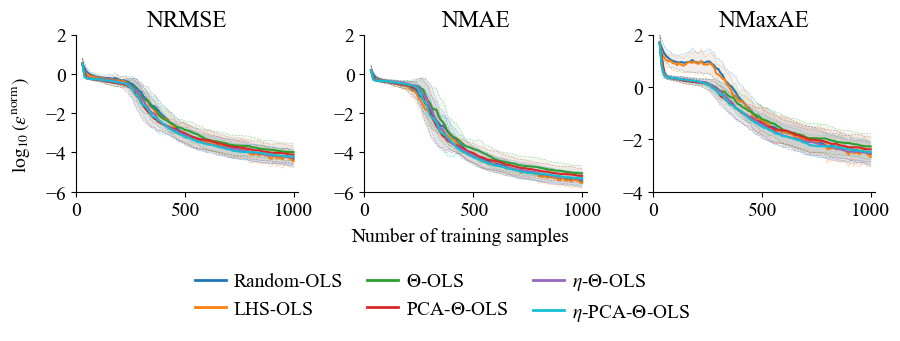

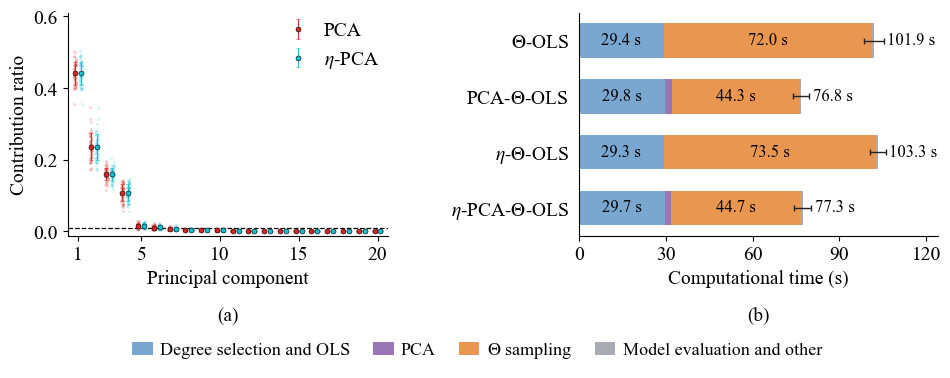

In [3]:
data=load_2d()
convergence(data)
pca_2d(data)

## Prescribed correlation matrix and representative fields

In [4]:
import numpy as np

EXAMPLE_NAME = "random_field"
BOUNDS = [(0.0, 1.0), (0.0, 1.0)]


def make_target_corr(n_outputs):
    group_ends = [0, min(8, n_outputs), min(12, n_outputs), min(16, n_outputs), min(20, n_outputs)]
    within = [0.95, 0.95, 0.85, 0.85]
    between = np.array([
        [1.00, 0.1, 0.05, 0.02],
        [0.1, 1.00, 0.08, 0.03],
        [0.05, 0.08, 1.00, 0.05],
        [0.02, 0.03, 0.05, 1.00],
    ])
    C = np.eye(n_outputs)
    groups = [range(group_ends[g], group_ends[g + 1]) for g in range(4)]
    for g, indices in enumerate(groups):
        for i in indices:
            for j in indices:
                if i != j:
                    C[i, j] = within[g]
    for g in range(4):
        for h in range(g + 1, 4):
            for i in groups[g]:
                for j in groups[h]:
                    C[i, j] = C[j, i] = between[g, h]
    return C


def matrix_square_root(C):
    values, vectors = np.linalg.eigh(C)
    return vectors @ np.diag(np.sqrt(np.maximum(values, 1e-12))) @ vectors.T


def modes(modes_per_dim):
    return [
        (kind, m, n)
        for m in range(1, modes_per_dim + 1)
        for n in range(1, modes_per_dim + 1)
        for kind in ("ss", "cs", "sc")
    ]


def evaluate_modes(X, mode_list):
    X = np.asarray(X, dtype=float)
    x1, x2 = X[:, 0], X[:, 1]
    Phi = np.empty((len(X), len(mode_list)))
    for k, (kind, m, n) in enumerate(mode_list):
        if kind == "ss":
            Phi[:, k] = np.sin(m * np.pi * x1) * np.sin(n * np.pi * x2)
        elif kind == "cs":
            Phi[:, k] = np.cos(m * np.pi * x1) * np.sin(n * np.pi * x2)
        else:
            Phi[:, k] = np.sin(m * np.pi * x1) * np.cos(n * np.pi * x2)
    return Phi


def build_model(args):
    rng = np.random.default_rng(args.field_seed)
    mode_list = modes(args.modes_per_dim)
    weights = np.asarray([
        np.exp(-args.corr_decay * (m**2 + n**2))
        for _, m, n in mode_list
    ])
    weights /= weights.sum()
    C_target = make_target_corr(args.n_outputs)
    A = rng.standard_normal((len(mode_list), args.n_outputs)) @ matrix_square_root(C_target).T
    coefficient_matrix = np.sqrt(weights)[:, None] * A

    # Match the earlier implementation: standardize each output using a fixed dense grid.
    axis = np.linspace(0.0, 1.0, 80)
    X1, X2 = np.meshgrid(axis, axis)
    calibration = np.column_stack([X1.ravel(), X2.ravel()])
    raw = evaluate_modes(calibration, mode_list) @ coefficient_matrix
    mean = raw.mean(axis=0)
    std = np.maximum(raw.std(axis=0, ddof=1), np.finfo(float).tiny)

    def evaluate(X):
        values = evaluate_modes(X, mode_list) @ coefficient_matrix
        return (values - mean) / std

    metadata = {
        "field_seed": args.field_seed,
        "n_outputs": args.n_outputs,
        "modes_per_dim": args.modes_per_dim,
        "corr_decay": args.corr_decay,
        "modes": mode_list,
        "weights": weights,
        "coefficient_matrix": coefficient_matrix,
        "target_correlation": C_target,
        "field_mean": mean,
        "field_std": std,
    }
    return evaluate, metadata

Field seed       : 2026
Modes per dim    : 5
Total modes      : 75
Correlation decay: 0.1


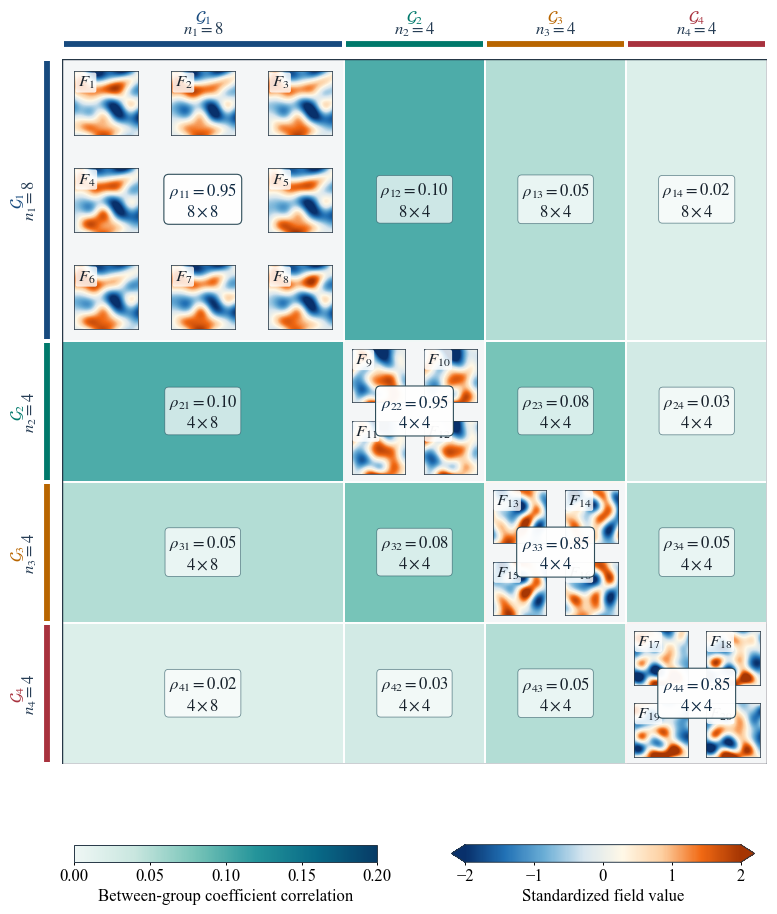

Saved:
rf_block_matrix.pdf


In [5]:
import matplotlib

from pathlib import Path
import importlib.util
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import (
    LinearSegmentedColormap,
    Normalize,
    TwoSlopeNorm,
)
from matplotlib.patches import Rectangle


# ================================================================
# 1. Figure settings
# ================================================================

FONT_SIZE = 12

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


rf_model=SimpleNamespace(build_model=build_model)

# ================================================================
# 3. Generate the same fixed realization used by the experiment
# ================================================================

FIELD_SEED = 2026
N_OUTPUTS = 20
MODES_PER_DIM = 5
CORR_DECAY = 0.1
N_PLOT_GRID = 151

model_args = SimpleNamespace(
    field_seed=FIELD_SEED,
    n_outputs=N_OUTPUTS,
    modes_per_dim=MODES_PER_DIM,
    corr_decay=CORR_DECAY,
)

evaluate_field, model_metadata = rf_model.build_model(
    model_args
)

grid_1d = np.linspace(0.0, 1.0, N_PLOT_GRID)
X1_grid, X2_grid = np.meshgrid(
    grid_1d,
    grid_1d,
    indexing="xy",
)

X_plot = np.column_stack((
    X1_grid.ravel(),
    X2_grid.ravel(),
))

Y_plot = evaluate_field(X_plot)

field_values = Y_plot.reshape(
    N_PLOT_GRID,
    N_PLOT_GRID,
    N_OUTPUTS,
)

print("Field seed       :", FIELD_SEED)
print("Modes per dim    :", MODES_PER_DIM)
print("Total modes      :", len(model_metadata["weights"]))
print("Correlation decay:", CORR_DECAY)


# ================================================================
# 4. Group and correlation definitions
# ================================================================

group_sizes = np.array([8, 4, 4, 4], dtype=int)
group_boundaries = np.concatenate((
    [0],
    np.cumsum(group_sizes),
))

group_labels = [
    r"$\mathcal{G}_1$",
    r"$\mathcal{G}_2$",
    r"$\mathcal{G}_3$",
    r"$\mathcal{G}_4$",
]

group_output_indices = [
    list(range(0, 8)),
    list(range(8, 12)),
    list(range(12, 16)),
    list(range(16, 20)),
]

# Read the correlations from the actual model instead of duplicating them.
target_correlation = np.asarray(
    model_metadata["target_correlation"],
    dtype=float,
)

within_correlations = np.asarray([
    target_correlation[indices[0], indices[1]]
    for indices in group_output_indices
])

between_correlations = np.full((4, 4), np.nan, dtype=float)
for row_group in range(4):
    for col_group in range(4):
        if row_group != col_group:
            between_correlations[row_group, col_group] = target_correlation[
                group_output_indices[row_group][0],
                group_output_indices[col_group][0],
            ]

# Dark, saturated colors for group labels and boundary bars.
group_colors = [
    "#174A7E",
    "#00796B",
    "#B86500",
    "#A8323E",
]


# ================================================================
# 5. Colormaps
# ================================================================

# Between-group correlation:
# pale blue-green -> teal -> dark blue.
correlation_cmap = LinearSegmentedColormap.from_list(
    "coefficient_correlation",
    [
        "#EFF7F5",
        "#C8E6DF",
        "#77C4B8",
        "#24949A",
        "#086A87",
        "#073B66",
    ],
    N=256,
)

correlation_norm = Normalize(
    vmin=0.0,
    vmax=0.20,
)

# Standardized output fields:
# dark blue -> blue -> pale neutral -> orange -> dark red.
field_cmap = LinearSegmentedColormap.from_list(
    "standardized_field",
    [
        "#08306B",
        "#2171B5",
        "#6BAED6",
        "#D7E6EF",
        "#FFF8E7",
        "#FDD0A2",
        "#F16913",
        "#A63603",
    ],
    N=256,
)

field_norm = TwoSlopeNorm(
    vmin=-2.0,
    vcenter=0.0,
    vmax=2.0,
)


# ================================================================
# 6. Helper functions
# ================================================================

def contrasting_text_color(rgba):
    """
    Select dark or white text according to the perceived
    luminance of the block background.
    """
    red, green, blue = rgba[:3]

    luminance = (
        0.2126 * red
        + 0.7152 * green
        + 0.0722 * blue
    )

    return "#FFFFFF" if luminance < 0.53 else "#17212B"


def add_field_inset(
    parent_axis,
    field,
    x_data,
    y_data,
    width_data,
    height_data,
    output_index,
):
    """
    Add a random-field thumbnail at a position expressed in
    the 20-by-20 matrix coordinate system.
    """
    total_size = float(group_sizes.sum())

    inset_bounds = [
        x_data / total_size,
        1.0 - (y_data + height_data) / total_size,
        width_data / total_size,
        height_data / total_size,
    ]

    inset_axis = parent_axis.inset_axes(
        inset_bounds,
        transform=parent_axis.transAxes,
        zorder=8,
    )

    inset_axis.imshow(
        field,
        origin="lower",
        extent=[0.0, 1.0, 0.0, 1.0],
        cmap=field_cmap,
        norm=field_norm,
        interpolation="bilinear",
        aspect="auto",
        rasterized=True,
    )

    inset_axis.set_xticks([])
    inset_axis.set_yticks([])

    for spine in inset_axis.spines.values():
        spine.set_visible(True)
        spine.set_color("#263746")
        spine.set_linewidth(0.55)

    inset_axis.text(
        0.055,
        0.945,
        rf"$F_{{{output_index + 1}}}$",
        transform=inset_axis.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_SIZE,
        color="#17212B",
        bbox={
            "boxstyle": "round,pad=0.12",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.82,
        },
        zorder=10,
    )


def add_center_annotation(
    axis,
    center_x,
    center_y,
    rho_value,
    rho_index,
    n_row,
    n_col,
    fontsize=FONT_SIZE,
):
    """
    Add a framed annotation containing the correlation and
    the actual matrix-block dimension.
    """
    annotation_text = (
        rf"$\rho_{{{rho_index}{rho_index}}}={rho_value:.2f}$"
        "\n"
        rf"${n_row}\times {n_col}$"
    )

    axis.text(
        center_x,
        center_y,
        annotation_text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color="#102A43",
        linespacing=1.25,
        zorder=15,
        bbox={
            "boxstyle": "round,pad=0.30",
            "facecolor": "#FFFFFF",
            "edgecolor": "#264653",
            "linewidth": 0.8,
            "alpha": 0.96,
        },
    )


# ================================================================
# 7. Create the main matrix
# ================================================================

fig, ax = plt.subplots(
    figsize=(10.2, 9.8),
)

fig.subplots_adjust(
    left=0.13,
    right=0.975,
    top=0.90,
    bottom=0.18,
)

total_dimension = int(group_sizes.sum())

ax.set_xlim(0.0, total_dimension)
ax.set_ylim(total_dimension, 0.0)
ax.set_aspect("equal")

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)


# ================================================================
# 8. Draw all matrix blocks
# ================================================================

for row_group in range(4):
    y_start = group_boundaries[row_group]
    block_height = group_sizes[row_group]

    for col_group in range(4):
        x_start = group_boundaries[col_group]
        block_width = group_sizes[col_group]

        if row_group == col_group:
            facecolor = "#F4F6F7"
            edgecolor = group_colors[row_group]
            line_width = 1.25

        else:
            rho = between_correlations[
                row_group,
                col_group,
            ]

            facecolor = correlation_cmap(
                correlation_norm(rho)
            )
            edgecolor = "#FFFFFF"
            line_width = 1.15

        block = Rectangle(
            (x_start, y_start),
            block_width,
            block_height,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=line_width,
            zorder=1,
        )
        ax.add_patch(block)

        if row_group != col_group:
            rho = between_correlations[
                row_group,
                col_group,
            ]

            text_color = contrasting_text_color(
                correlation_cmap(
                    correlation_norm(rho)
                )
            )

            block_text = (
                rf"$\rho_{{{row_group + 1}{col_group + 1}}}"
                rf"={rho:.2f}$"
                "\n"
                rf"${block_height}\times{block_width}$"
            )

            ax.text(
                x_start + block_width / 2.0,
                y_start + block_height / 2.0,
                block_text,
                ha="center",
                va="center",
                fontsize=FONT_SIZE,
                fontweight="semibold",
                color=text_color,
                linespacing=1.35,
                zorder=5,
                bbox={
                    "boxstyle": "round,pad=0.23",
                    "facecolor": (
                        "#FFFFFF"
                        if text_color != "#FFFFFF"
                        else "#0B2638"
                    ),
                    "edgecolor": (
                        "#315B67"
                        if text_color != "#FFFFFF"
                        else "#FFFFFF"
                    ),
                    "linewidth": 0.55,
                    "alpha": (
                        0.72
                        if text_color != "#FFFFFF"
                        else 0.32
                    ),
                },
            )


# ================================================================
# 9. Place all fields inside the diagonal blocks
# ================================================================

# ------------------------------------------------
# Group G1: eight fields in a 3-by-3 ring
# ------------------------------------------------

g1_start = group_boundaries[0]
g1_size = group_sizes[0]

g1_thumbnail_size = 1.80
g1_positions_1d = np.linspace(
    g1_start + 0.35,
    g1_start + g1_size - 0.35 - g1_thumbnail_size,
    3,
)

g1_ring_positions = [
    (0, 0),
    (1, 0),
    (2, 0),
    (0, 1),
    (2, 1),
    (0, 2),
    (1, 2),
    (2, 2),
]

for output_index, (col_position, row_position) in zip(
    group_output_indices[0],
    g1_ring_positions,
):
    add_field_inset(
        parent_axis=ax,
        field=field_values[:, :, output_index],
        x_data=g1_positions_1d[col_position],
        y_data=g1_positions_1d[row_position],
        width_data=g1_thumbnail_size,
        height_data=g1_thumbnail_size,
        output_index=output_index,
    )

add_center_annotation(
    axis=ax,
    center_x=g1_start + g1_size / 2.0,
    center_y=g1_start + g1_size / 2.0,
    rho_value=within_correlations[0],
    rho_index=1,
    n_row=g1_size,
    n_col=g1_size,
    fontsize=FONT_SIZE,
)


# ------------------------------------------------
# Groups G2, G3, and G4: four fields in 2-by-2 grids
# ------------------------------------------------

for group_index in range(1, 4):
    group_start = group_boundaries[group_index]
    group_size = group_sizes[group_index]

    thumbnail_size = 1.52
    edge_padding = 0.22

    thumbnail_positions = [
        group_start + edge_padding,
        group_start + group_size
        - edge_padding
        - thumbnail_size,
    ]

    corner_positions = [
        (0, 0),
        (1, 0),
        (0, 1),
        (1, 1),
    ]

    for output_index, (col_position, row_position) in zip(
        group_output_indices[group_index],
        corner_positions,
    ):
        add_field_inset(
            parent_axis=ax,
            field=field_values[:, :, output_index],
            x_data=thumbnail_positions[col_position],
            y_data=thumbnail_positions[row_position],
            width_data=thumbnail_size,
            height_data=thumbnail_size,
            output_index=output_index,
        )

    add_center_annotation(
        axis=ax,
        center_x=group_start + group_size / 2.0,
        center_y=group_start + group_size / 2.0,
        rho_value=within_correlations[group_index],
        rho_index=group_index + 1,
        n_row=group_size,
        n_col=group_size,
        fontsize=FONT_SIZE,
    )


# ================================================================
# 10. Draw group bars and external labels
# ================================================================

for group_index in range(4):
    group_start = group_boundaries[group_index]
    group_size = group_sizes[group_index]
    group_center = group_start + group_size / 2.0
    group_color = group_colors[group_index]

    # Top group bar.
    ax.plot(
        [
            group_start + 0.06,
            group_start + group_size - 0.06,
        ],
        [-0.43, -0.43],
        color=group_color,
        linewidth=4.2,
        solid_capstyle="butt",
        clip_on=False,
        zorder=20,
    )

    # Left group bar.
    ax.plot(
        [-0.43, -0.43],
        [
            group_start + 0.06,
            group_start + group_size - 0.06,
        ],
        color=group_color,
        linewidth=4.2,
        solid_capstyle="butt",
        clip_on=False,
        zorder=20,
    )

    # Column label.
    ax.text(
        group_center,
        -0.92,
        group_labels[group_index],
        ha="center",
        va="bottom",
        fontsize=FONT_SIZE,
        fontweight="bold",
        color=group_color,
        clip_on=False,
    )

    ax.text(
        group_center,
        -0.58,
        rf"$n_{group_index + 1}={group_size}$",
        ha="center",
        va="bottom",
        fontsize=FONT_SIZE,
        fontweight="semibold",
        color="#243B53",
        clip_on=False,
    )

    # Row label.
    ax.text(
        -0.98,
        group_center,
        group_labels[group_index],
        ha="right",
        va="center",
        rotation=90,
        fontsize=FONT_SIZE,
        fontweight="bold",
        color=group_color,
        clip_on=False,
    )

    ax.text(
        -0.63,
        group_center,
        rf"$n_{group_index + 1}={group_size}$",
        ha="right",
        va="center",
        rotation=90,
        fontsize=FONT_SIZE,
        fontweight="semibold",
        color="#243B53",
        clip_on=False,
    )


# ================================================================
# 11. Matrix boundary lines
# ================================================================

for boundary in group_boundaries:
    ax.plot(
        [boundary, boundary],
        [0.0, total_dimension],
        color="#FFFFFF",
        linewidth=1.35,
        zorder=6,
    )
    ax.plot(
        [0.0, total_dimension],
        [boundary, boundary],
        color="#FFFFFF",
        linewidth=1.35,
        zorder=6,
    )

ax.add_patch(
    Rectangle(
        (0.0, 0.0),
        total_dimension,
        total_dimension,
        fill=False,
        edgecolor="#263746",
        linewidth=1.05,
        zorder=21,
    )
)


# ================================================================
# 12. Colorbars
# ================================================================

correlation_scalar_map = mpl.cm.ScalarMappable(
    norm=correlation_norm,
    cmap=correlation_cmap,
)
correlation_scalar_map.set_array([])

field_scalar_map = mpl.cm.ScalarMappable(
    norm=field_norm,
    cmap=field_cmap,
)
field_scalar_map.set_array([])


# Draw once so that ax.get_position() returns the final position
# after the equal-aspect adjustment.
fig.canvas.draw()

matrix_box = ax.get_position()

matrix_left = matrix_box.x0
matrix_right = matrix_box.x1
matrix_bottom = matrix_box.y0
matrix_width = matrix_box.width

# The two colorbars are aligned with the outer matrix frame,
# with a small inset at both ends and a central gap.
outer_inset = 0.018 * matrix_width
center_gap = 0.105 * matrix_width

colorbar_width = (
    matrix_width
    - 2.0 * outer_inset
    - center_gap
) / 2.0

colorbar_height = 0.018
colorbar_vertical_gap = 0.100

colorbar_bottom = (
    matrix_bottom
    - colorbar_vertical_gap
)

left_colorbar_left = (
    matrix_left
    + outer_inset
)

right_colorbar_left = (
    matrix_right
    - outer_inset
    - colorbar_width
)


# ------------------------------------------------
# Left colorbar: between-group coefficient correlation
# ------------------------------------------------

correlation_cbar_axis = fig.add_axes([
    left_colorbar_left,
    colorbar_bottom,
    colorbar_width,
    colorbar_height,
])

correlation_cbar = fig.colorbar(
    correlation_scalar_map,
    cax=correlation_cbar_axis,
    orientation="horizontal",
    ticks=[
        0.00,
        0.05,
        0.10,
        0.15,
        0.20,
    ],
)

correlation_cbar.set_label(
    "Between-group coefficient correlation",
    labelpad=3.0,
)

correlation_cbar.ax.tick_params(
    length=2.5,
    width=0.7,
    pad=1.5,
    labelsize=FONT_SIZE
)

correlation_cbar.outline.set_linewidth(
    0.7
)

correlation_cbar.outline.set_edgecolor(
    "#263746"
)


# ------------------------------------------------
# Right colorbar: standardized field values
# ------------------------------------------------

field_cbar_axis = fig.add_axes([
    right_colorbar_left,
    colorbar_bottom,
    colorbar_width,
    colorbar_height,
])

field_cbar = fig.colorbar(
    field_scalar_map,
    cax=field_cbar_axis,
    orientation="horizontal",
    ticks=[
        -2,
        -1,
        0,
        1,
        2,
    ],
    extend="both",
)

field_cbar.set_label(
    "Standardized field value",
    labelpad=3.0,
)

field_cbar.ax.tick_params(
    length=2.5,
    width=0.7,
    pad=1.5,
    labelsize=FONT_SIZE
)

field_cbar.outline.set_linewidth(
    0.7
)

field_cbar.outline.set_edgecolor(
    "#263746"
)


# ================================================================
# 13. Save and display
# ================================================================

output_file = (
    FIG
    / "rf_block_matrix.pdf"
)

fig.savefig(
    output_file,
    bbox_inches="tight",
    pad_inches=0.04,
    dpi=400,
)


display(fig); plt.close(fig)

print("Saved:")
print(output_file.name)